# Import Libraries

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import sys

sys.path.insert(0, os.path.abspath(".."))
from src.data_loader import load_dataset

In [5]:
# load dataset
df = pd.read_csv("../data/raw/customer_churn_data.csv")

In [6]:
# first 5 rows
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,CUST0000,Male,0,No,Yes,23,No,No phone service,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Bank transfer,49.85,1146.55,No
1,CUST0001,Female,0,Yes,No,43,No,No phone service,DSL,Yes,...,Yes,No,Yes,No,Month-to-month,No,Mailed check,100.70,4330.10,Yes
2,CUST0002,Male,1,No,No,51,Yes,No,DSL,No,...,Yes,Yes,No,No,One year,No,Electronic check,97.33,4963.83,Yes
3,CUST0003,Male,1,No,No,72,Yes,Yes,DSL,Yes,...,Yes,No,No,No,Month-to-month,No,Credit card,101.38,7299.36,No
4,CUST0004,Male,1,No,No,25,Yes,Yes,DSL,No,...,No,Yes,No,Yes,Month-to-month,No,Electronic check,52.22,1305.50,Yes


In [8]:
# dataset shape
df.shape

(5880, 21)

In [9]:
# dataset shape
print(df.shape)

(5880, 21)


In [10]:
# dataset info
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5880 entries, 0 to 5879
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        5880 non-null   str    
 1   gender            5880 non-null   str    
 2   SeniorCitizen     5880 non-null   int64  
 3   Partner           5880 non-null   str    
 4   Dependents        5880 non-null   str    
 5   tenure            5880 non-null   int64  
 6   PhoneService      5880 non-null   str    
 7   MultipleLines     5880 non-null   str    
 8   InternetService   5880 non-null   str    
 9   OnlineSecurity    5880 non-null   str    
 10  OnlineBackup      5880 non-null   str    
 11  DeviceProtection  5880 non-null   str    
 12  TechSupport       5880 non-null   str    
 13  StreamingTV       5880 non-null   str    
 14  StreamingMovies   5880 non-null   str    
 15  Contract          5880 non-null   str    
 16  PaperlessBilling  5880 non-null   str    
 17  Paymen

In [13]:
# summary (statistics) of the dataset
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,5880.000000,5880.000000,5880.000000,5880.000000
mean,0.500680,36.549150,70.157779,2566.813165
std,0.500042,20.909674,28.804615,1910.017743
min,0.000000,1.000000,20.000000,20.030000
25%,0.000000,18.000000,45.717500,1020.217500
50%,1.000000,37.000000,70.155000,2136.445000
75%,1.000000,55.000000,95.457500,3767.665000
max,1.000000,72.000000,119.990000,8589.600000


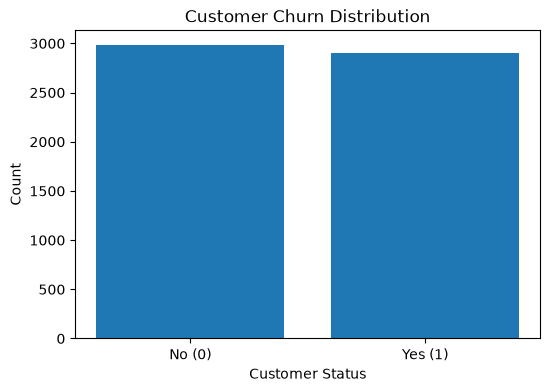

In [16]:
# target distribution
churn_counts = df["Churn"].value_counts()

plt.figure(figsize=(6,4))
plt.bar(["No (0)", "Yes (1)"], churn_counts.values)
plt.title("Customer Churn Distribution")
plt.xlabel("Customer Status")
plt.ylabel("Count")
plt.show()

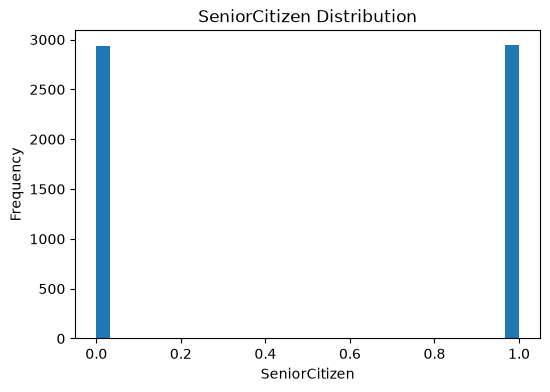

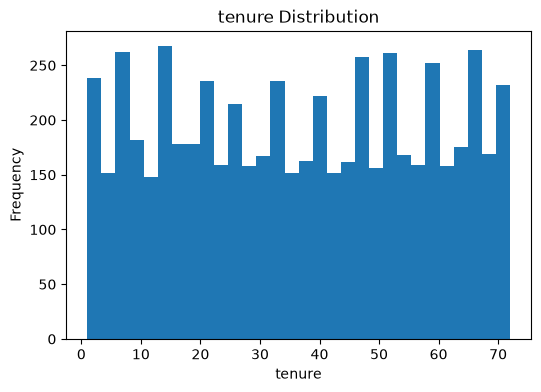

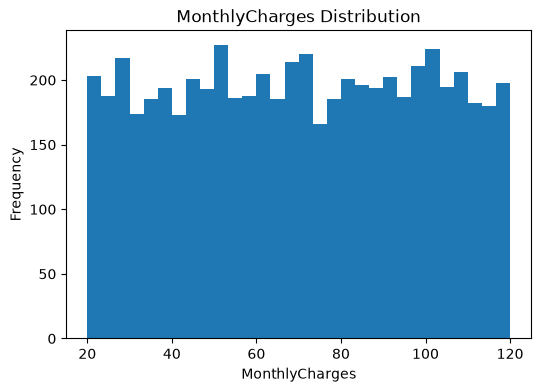

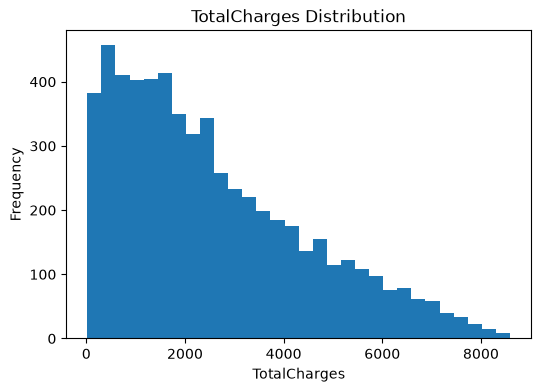

In [17]:
# numerical features distribution
numerical_features = [
    "SeniorCitizen", 
    "tenure", 
    "MonthlyCharges", 
    "TotalCharges"
]

for column in numerical_features:
    plt.figure(figsize=(6,4))
    plt.hist(df[column], bins=30)
    plt.title(f"{column} Distribution")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.show()

/var/folders/_k/br6984v13bd646948vbf7zvw0000gn/T/ipykernel_5743/1862091750.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[column], vert=False)


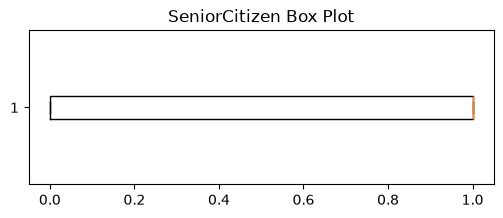

/var/folders/_k/br6984v13bd646948vbf7zvw0000gn/T/ipykernel_5743/1862091750.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[column], vert=False)


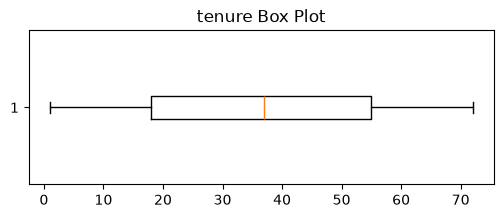

/var/folders/_k/br6984v13bd646948vbf7zvw0000gn/T/ipykernel_5743/1862091750.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[column], vert=False)


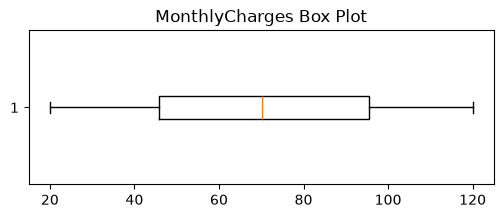

/var/folders/_k/br6984v13bd646948vbf7zvw0000gn/T/ipykernel_5743/1862091750.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[column], vert=False)


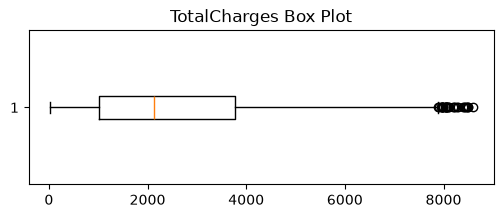

In [18]:
# boxplots (outliers)
for column in numerical_features:
    plt.figure(figsize=(6,2))
    plt.boxplot(df[column], vert=False)
    plt.title(f"{column} Box Plot")
    plt.show()

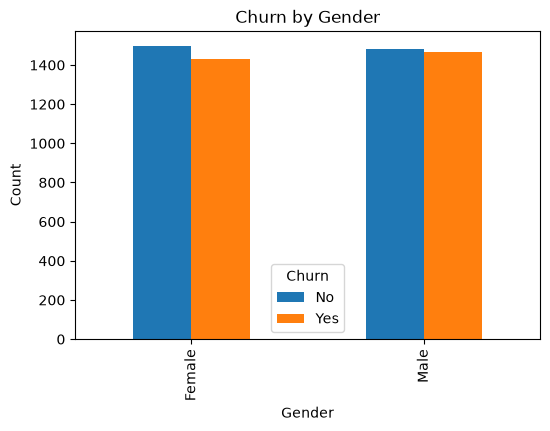

In [21]:
# churn rate by categorical features
# GENDER
gender_churn = pd.crosstab(df["gender"], df["Churn"])

gender_churn.plot(kind="bar", figsize=(6,4))
plt.title("Churn by Gender")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.show()

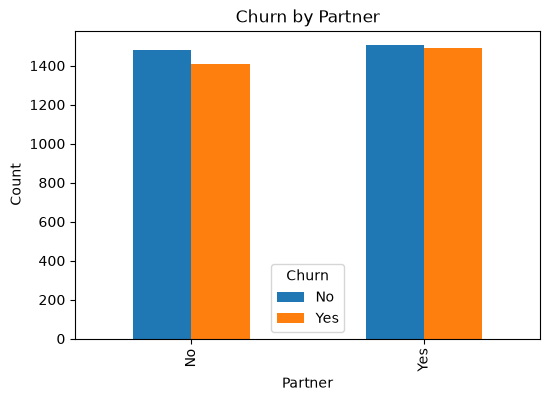

In [23]:
# churn rate by categorical features
# PARTNER
partner_churn = pd.crosstab(df["Partner"], df["Churn"])

partner_churn.plot(kind="bar", figsize=(6,4))
plt.title("Churn by Partner")
plt.xlabel("Partner")
plt.ylabel("Count")
plt.show()

In [24]:
# correlation analysis
# First, remove non-numeric identifier/text columns if necessary.
numeric_df = df.select_dtypes(include=["int64", "float64"])

corr = numeric_df.corr()

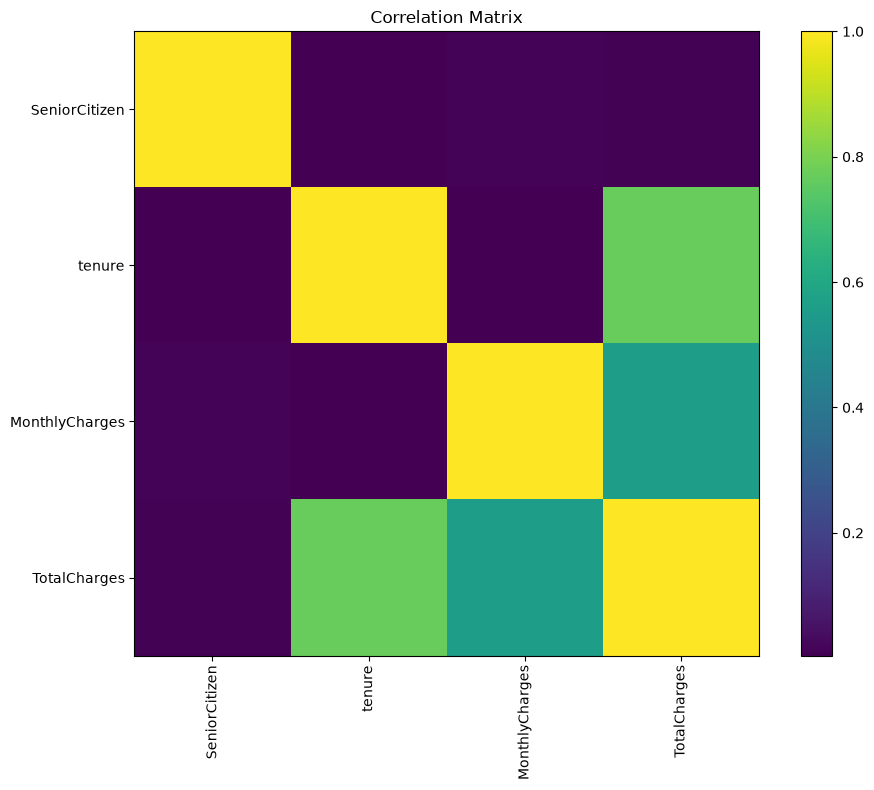

In [25]:
# visualize
plt.figure(figsize=(10,8))
plt.imshow(corr, interpolation="nearest")
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

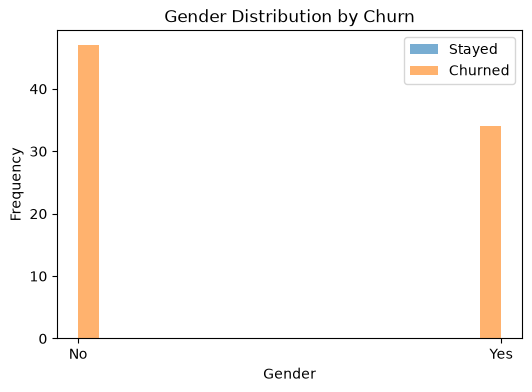

In [ ]:
# tenure vs churn
plt.figure(figsize=(6,4))

plt.hist(df[df["Churn"] == 0]["tenure"], alpha=0.6, bins=20, label="Stayed")
plt.hist(df[df["tenure"] == 1]["Churn"], alpha=0.6, bins=20, label="Churned")

plt.xlabel("Tenure")
plt.ylabel("Frequency")
plt.title("Tenure Distribution by Churn")
plt.legend()
plt.show()

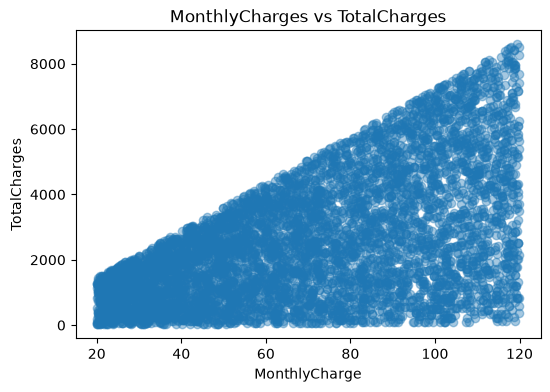

In [34]:
# charges vs churn
plt.figure(figsize=(6,4))

plt.scatter(
    df["MonthlyCharges"],
    df["TotalCharges"],
    alpha=0.4
)

plt.xlabel("MonthlyCharge")
plt.ylabel("TotalCharges")
plt.title("MonthlyCharges vs TotalCharges")
plt.show()